# Section 3 — Image Filtering, Thresholding & Edge Detection

### Clean and Analyze Images

In the previous sections, we learned how to:
- read and write images with OpenCV
- understand color spaces
- work with NumPy arrays and image `dtype`
- augment and annotate images
- create masks and use bitwise operations
- draw shapes and text

Now we will learn how to **clean images, separate objects from their background, modify object shapes, and detect boundaries**.

### Learning goals

By the end of this section, you should be able to:

1. Explain why images contain noise.
2. Add and visualize Gaussian and salt-and-pepper noise.
3. Apply smoothing filters and understand their differences.
4. Separate foreground and background using thresholding.
5. Compare binary, inverse, adaptive, and Otsu thresholding.
6. Use erosion, dilation, opening, and closing.
7. Understand image derivatives and gradients.
8. Apply Sobel X/Y, gradient magnitude, Laplacian, and Canny edge detection.

### Main idea

We will follow this pipeline:

**Noise → Filtering → Thresholding → Morphology → Gradients → Edge Detection**

In [1]:
# Basic imports
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)

OpenCV version: 5.0.0
NumPy version: 2.1.3


## 0. Create a clean test image

To make the notebook reproducible, we will create a simple grayscale image containing:
- a rectangle
- a circle
- a smaller bright object
- a smooth background

We can use this same image throughout the lesson so that students can clearly see what each operation changes.

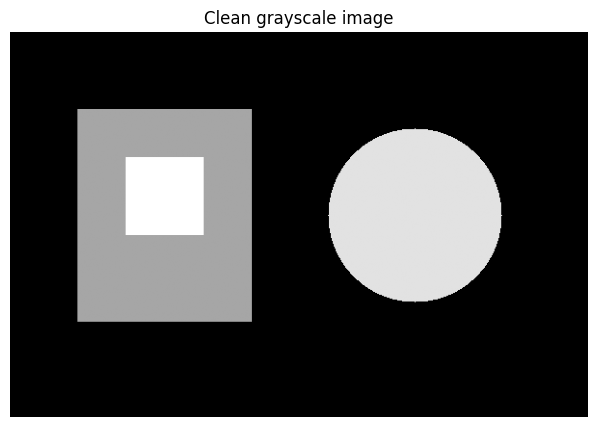

Shape: (400, 600)
dtype: uint8
Intensity range: 40 to 255


In [2]:
# Create a grayscale test image
img = np.zeros((400, 600), dtype=np.uint8)

# Smooth background
img[:] = 40

# Objects
cv2.rectangle(img, (70, 80), (250, 300), 180, -1)
cv2.circle(img, (420, 190), 90, 230, -1)
cv2.rectangle(img, (120, 130), (200, 210), 255, -1)

plt.figure(figsize=(9, 5))
plt.imshow(img, cmap="gray")
plt.title("Clean grayscale image")
plt.axis("off")
plt.show()

print("Shape:", img.shape)
print("dtype:", img.dtype)
print("Intensity range:", img.min(), "to", img.max())

# Lesson 1 — Noise and Image Quality

## What is noise?

**Noise** is unwanted random variation in pixel values.

Real images can contain noise because of:
- low light
- camera sensors
- transmission errors
- compression
- environmental conditions

Noise can make later algorithms less reliable.

For example, an edge detector may interpret a random noisy pixel as an edge.

We will study two common types:

### 1. Gaussian noise
Pixel values are changed using random values drawn from a Gaussian (normal) distribution.

### 2. Salt-and-pepper noise
Some pixels are randomly changed to extreme values:
- `0` → pepper
- `255` → salt

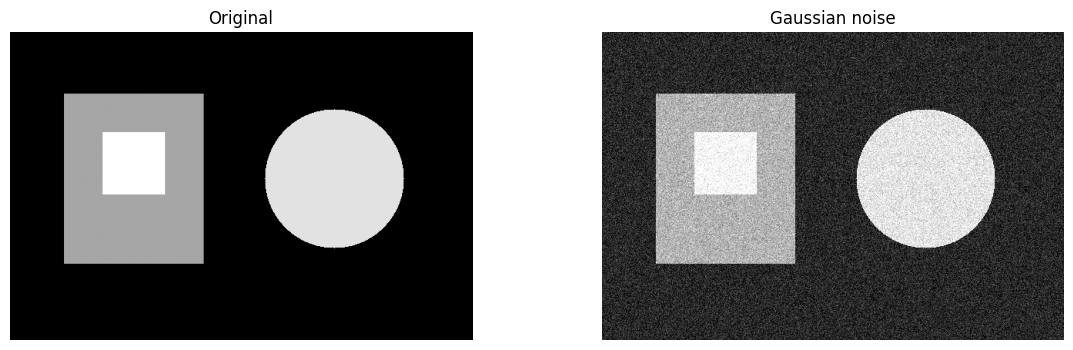

In [3]:
# Add Gaussian noise
def add_gaussian_noise(image, mean=0, sigma=25):
    noise = np.random.normal(mean, sigma, image.shape)
    noisy = image.astype(np.float32) + noise
    return np.clip(noisy, 0, 255).astype(np.uint8)

np.random.seed(42)
gaussian_noisy = add_gaussian_noise(img, sigma=25)

plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gaussian_noisy, cmap="gray")
plt.title("Gaussian noise")
plt.axis("off")

plt.show()

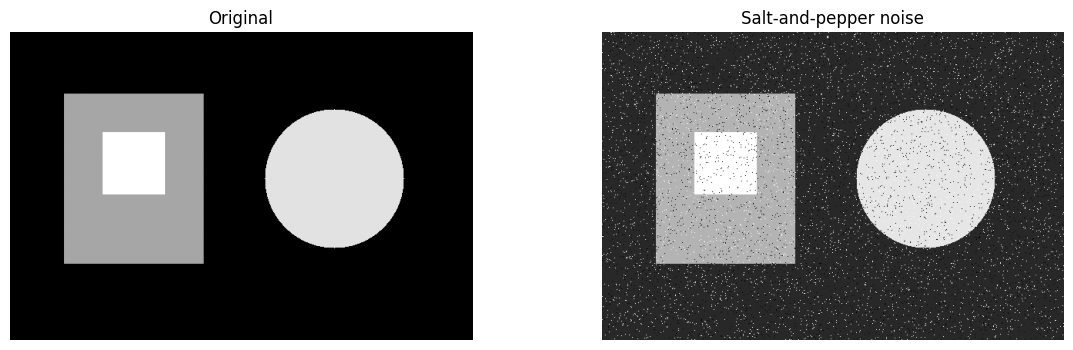

In [4]:
# Add salt-and-pepper noise
def add_salt_pepper_noise(image, amount=0.03):
    noisy = image.copy()
    total_pixels = image.size
    num_pixels = int(amount * total_pixels)

    # Pepper
    rows = np.random.randint(0, image.shape[0], num_pixels)
    cols = np.random.randint(0, image.shape[1], num_pixels)
    noisy[rows, cols] = 0

    # Salt
    rows = np.random.randint(0, image.shape[0], num_pixels)
    cols = np.random.randint(0, image.shape[1], num_pixels)
    noisy[rows, cols] = 255

    return noisy

np.random.seed(42)
sp_noisy = add_salt_pepper_noise(img, amount=0.02)

plt.figure(figsize=(14, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sp_noisy, cmap="gray")
plt.title("Salt-and-pepper noise")
plt.axis("off")

plt.show()

### Observation

Notice that the two noise types look different.

- **Gaussian noise** spreads small intensity changes across the image.
- **Salt-and-pepper noise** creates isolated very dark and very bright pixels.

This difference matters because different filters handle different noise types better.

# Lesson 2 — Image Filtering

Filtering changes a pixel using information from its neighborhood.

A simple way to think about filtering is:

> **The new pixel value depends on nearby pixels.**

We will compare:

- Average blur
- Gaussian blur
- Median blur
- Bilateral filtering

The main filters required for this section are **Gaussian blur** and **median blur**.

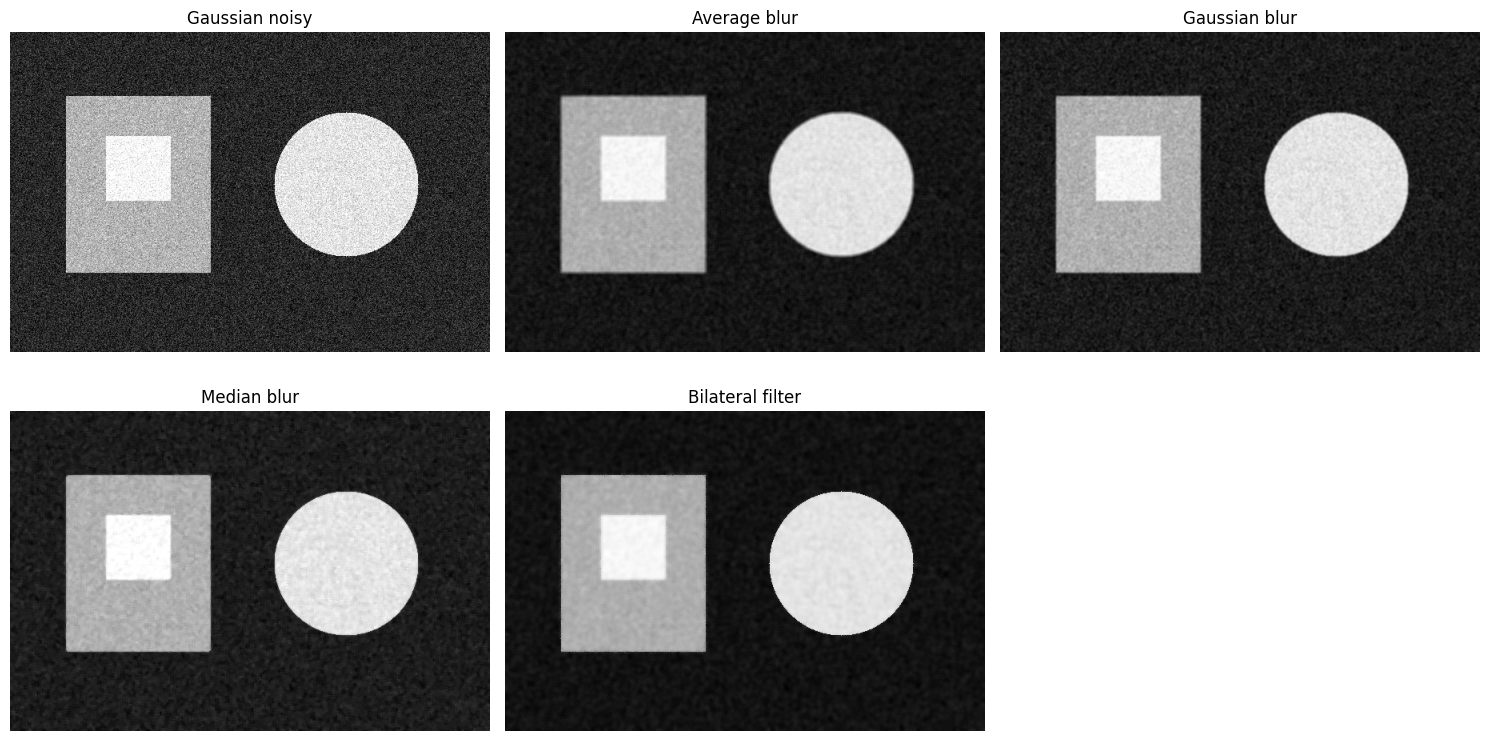

In [5]:
# Apply different filters to Gaussian noise
average = cv2.blur(gaussian_noisy, (5, 5))
gaussian = cv2.GaussianBlur(gaussian_noisy, (5, 5), 0)
median = cv2.medianBlur(gaussian_noisy, 5)
bilateral = cv2.bilateralFilter(gaussian_noisy, 9, 75, 75)

titles = [
    "Gaussian noisy",
    "Average blur",
    "Gaussian blur",
    "Median blur",
    "Bilateral filter"
]
images = [
    gaussian_noisy,
    average,
    gaussian,
    median,
    bilateral
]

plt.figure(figsize=(15, 8))
for i, (title, image) in enumerate(zip(titles, images), 1):
    plt.subplot(2, 3, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

## Gaussian Blur

`cv2.GaussianBlur()` gives more importance to pixels near the center of the neighborhood.

```python
blur = cv2.GaussianBlur(image, (5, 5), 0)
```

### Important idea

A larger kernel usually means stronger smoothing.

For example:

- `(3, 3)` → lighter smoothing
- `(5, 5)` → stronger smoothing
- `(9, 9)` → even stronger smoothing

The kernel size should normally be positive and odd.

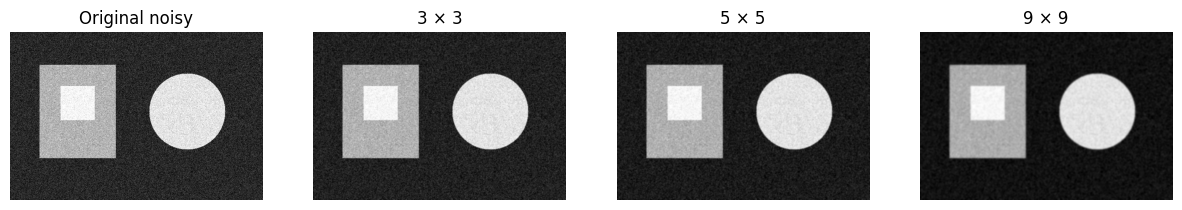

In [6]:
# Compare Gaussian kernel sizes
blur_3 = cv2.GaussianBlur(gaussian_noisy, (3, 3), 0)
blur_5 = cv2.GaussianBlur(gaussian_noisy, (5, 5), 0)
blur_9 = cv2.GaussianBlur(gaussian_noisy, (9, 9), 0)

plt.figure(figsize=(15, 4))

for i, (title, image) in enumerate([
    ("Original noisy", gaussian_noisy),
    ("3 × 3", blur_3),
    ("5 × 5", blur_5),
    ("9 × 9", blur_9)
], 1):
    plt.subplot(1, 4, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.show()

## Median Blur

`cv2.medianBlur()` replaces a pixel with the **median** of its neighborhood.

It is especially useful for **salt-and-pepper noise** because extreme values are less likely to survive the median operation.

Example:

Neighborhood:

`[20, 21, 22, 23, 255]`

Median:

`22`

The extreme `255` does not dominate the result.

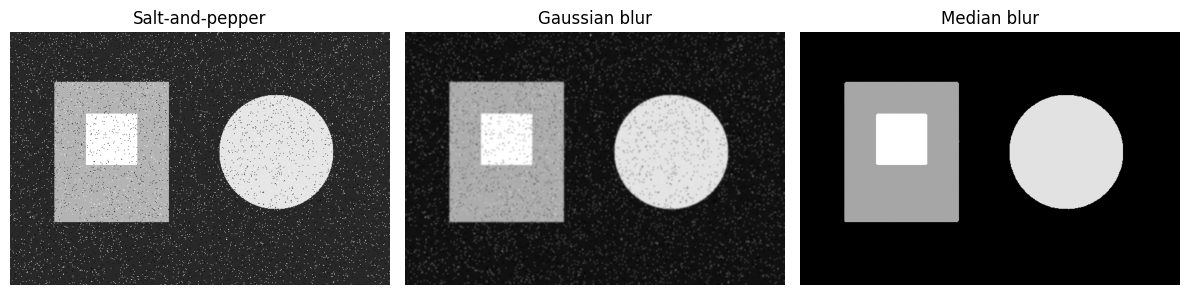

In [23]:
median_sp = cv2.medianBlur(sp_noisy, 5)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(sp_noisy, cmap="gray")
plt.title("Salt-and-pepper")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.GaussianBlur(sp_noisy, (5, 5), 0), cmap="gray")
plt.title("Gaussian blur")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(median_sp, cmap="gray")
plt.title("Median blur")
plt.axis("off")

plt.tight_layout()
plt.show()

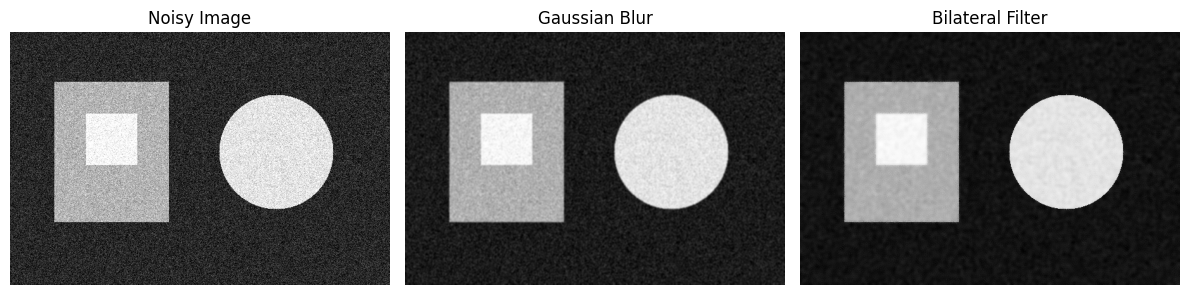

In [21]:
# Bilateral Filtering
# Reduces noise while trying to preserve important edges

bilateral = cv2.bilateralFilter(
    gaussian_noisy,
    d=9,
    sigmaColor=75,
    sigmaSpace=75
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(gaussian_noisy, cmap="gray")
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cv2.GaussianBlur(gaussian_noisy, (5, 5), 0), cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(bilateral, cmap="gray")
plt.title("Bilateral Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

### Filtering comparison

| Filter | Main idea | Good use |
|---|---|---|
| Average | Mean of neighborhood | Simple smoothing |
| Gaussian | Weighted smoothing | General noise reduction |
| Median | Median of neighborhood | Salt-and-pepper noise |
| Bilateral | Smooths while preserving edges | Noise reduction with edge preservation |

### Important trade-off

Filtering reduces noise, but **too much filtering can remove useful details and edges**.

So filtering is usually a balance:

**less noise ↔ preserve important structures**

# Lesson 3 — Image Thresholding

Thresholding converts an image into regions based on pixel intensity.

The basic idea is:

> If a pixel is brighter/darker than a chosen threshold, classify it differently.

For a simple binary threshold:

- intensity > threshold → `255`
- intensity ≤ threshold → `0`

This is one of the simplest forms of **image segmentation**.

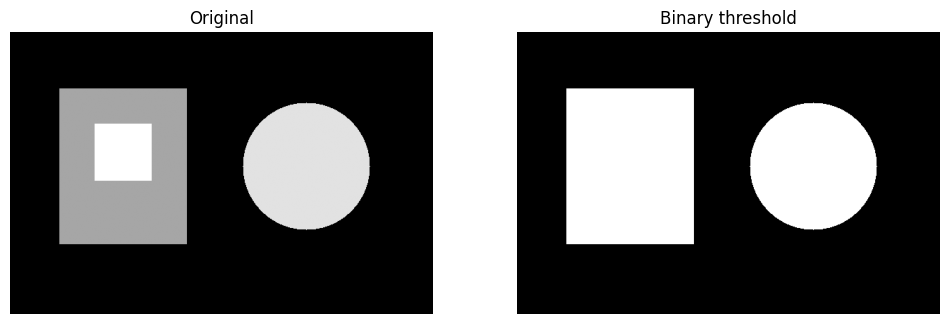

In [8]:
# Create a simple threshold
threshold_value = 120

_, binary = cv2.threshold(img, threshold_value, 255, cv2.THRESH_BINARY)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray")
plt.title("Binary threshold")
plt.axis("off")

plt.show()

## Binary vs Inverse Thresholding

OpenCV provides:

- `cv2.THRESH_BINARY`
- `cv2.THRESH_BINARY_INV`

They perform opposite classifications.

### Binary

Bright pixels become white.

### Binary inverse

Bright pixels become black and darker pixels become white.

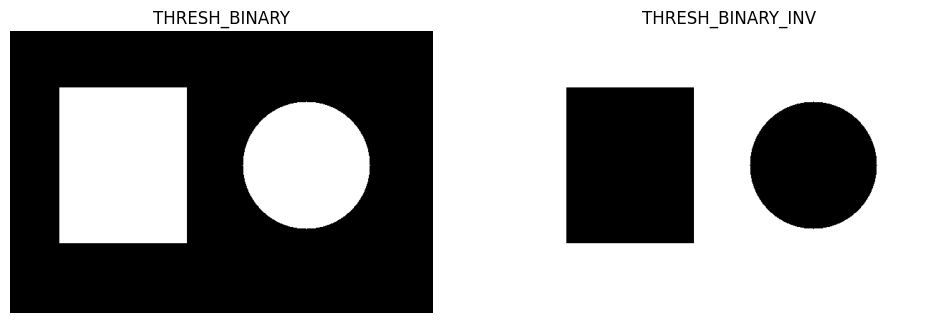

In [9]:
_, binary = cv2.threshold(img, 120, 255, cv2.THRESH_BINARY)
_, binary_inv = cv2.threshold(img, 120, 255, cv2.THRESH_BINARY_INV)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(binary, cmap="gray")
plt.title("THRESH_BINARY")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_inv, cmap="gray")
plt.title("THRESH_BINARY_INV")
plt.axis("off")

plt.show()

## Adaptive Thresholding

A single global threshold does not work well when lighting changes across an image.

Adaptive thresholding calculates a threshold from a **local neighborhood**.

OpenCV examples:

```python
cv2.ADAPTIVE_THRESH_MEAN_C
cv2.ADAPTIVE_THRESH_GAUSSIAN_C
```

This is useful for images such as documents photographed under uneven lighting.

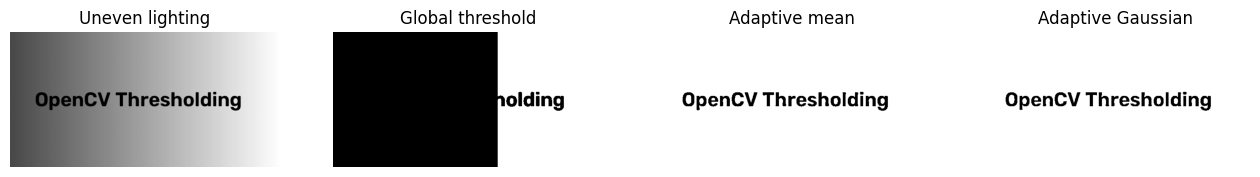

In [10]:
# Create a synthetic uneven-light document-like image
h, w = 300, 600
x = np.linspace(0, 1, w)
gradient = np.tile((60 + 100 * x).astype(np.uint8), (h, 1))

document = gradient.copy()

cv2.putText(
    document, "OpenCV Thresholding",
    (55, 165),
    cv2.FONT_HERSHEY_SIMPLEX,
    1.5, 20, 3, cv2.LINE_AA
)

global_binary = cv2.threshold(document, 120, 255, cv2.THRESH_BINARY)[1]

adaptive_mean = cv2.adaptiveThreshold(
    document, 255,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY,
    21, 5
)

adaptive_gaussian = cv2.adaptiveThreshold(
    document, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    21, 5
)

plt.figure(figsize=(16, 4))

for i, (title, image) in enumerate([
    ("Uneven lighting", document),
    ("Global threshold", global_binary),
    ("Adaptive mean", adaptive_mean),
    ("Adaptive Gaussian", adaptive_gaussian)
], 1):
    plt.subplot(1, 4, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.show()

## Otsu Thresholding

Sometimes we do not know the best threshold value.

Otsu's method automatically chooses a threshold by analyzing the intensity distribution.

```python
threshold, result = cv2.threshold(
    image, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
```

The returned `threshold` is the threshold value selected by Otsu's method.

Otsu selected threshold: 40.0


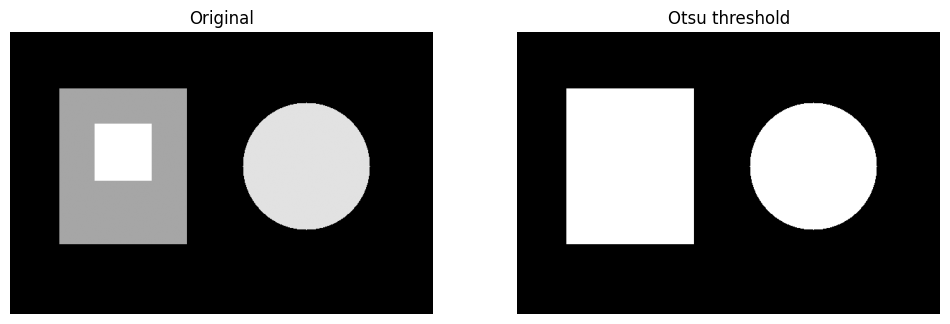

In [11]:
otsu_threshold, otsu = cv2.threshold(
    img, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Otsu selected threshold:", otsu_threshold)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(otsu, cmap="gray")
plt.title("Otsu threshold")
plt.axis("off")

plt.show()

### Thresholding decision guide

| Method | When to use |
|---|---|
| Binary | You know a suitable global threshold |
| Binary inverse | You need the opposite foreground/background |
| Adaptive | Lighting changes across the image |
| Otsu | You want an automatic global threshold and the histogram is reasonably bimodal |

### Key question

Before choosing a thresholding method, ask:

**Is one threshold suitable for the whole image?**

If yes → global methods may work.

If no → adaptive thresholding may be better.

# Lesson 4 — Morphological Operations

Morphology works mainly with **binary images** and a small shape called a **kernel** or **structuring element**.

The four core operations are:

1. Erosion
2. Dilation
3. Opening
4. Closing

These operations change the shape and connectivity of foreground regions.

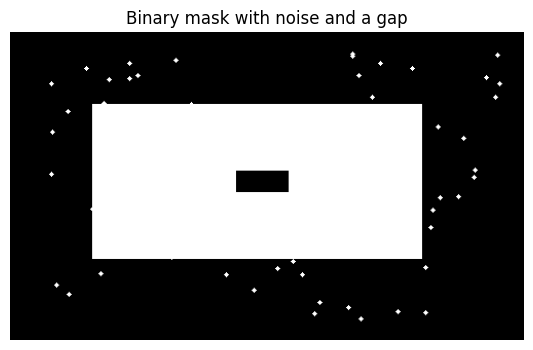

In [7]:
# Create a binary image with small noise and a small gap
mask = np.zeros((300, 500), dtype=np.uint8)

cv2.rectangle(mask, (80, 70), (400, 220), 255, -1)

# Add small foreground noise
np.random.seed(1)
for _ in range(80):
    x = np.random.randint(20, 480)
    y = np.random.randint(20, 280)
    cv2.circle(mask, (x, y), 2, 255, -1)

# Add a small black gap inside the object
cv2.rectangle(mask, (220, 135), (270, 155), 0, -1)

plt.figure(figsize=(8, 4))
plt.imshow(mask, cmap="gray")
plt.title("Binary mask with noise and a gap")
plt.axis("off")
plt.show()

## Kernel

A kernel defines the neighborhood used by a morphological operation.

```python
kernel = np.ones((5, 5), np.uint8)
```

You can change its size to change the strength of the operation.

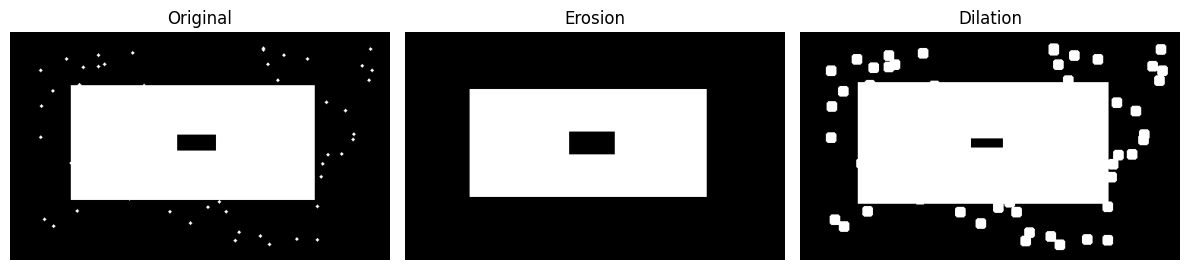

In [10]:
kernel = np.ones((10, 10), np.uint8)

erosion = cv2.erode(mask, kernel, iterations=1)
dilation = cv2.dilate(mask, kernel, iterations=1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(mask, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(erosion, cmap="gray")
plt.title("Erosion")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(dilation, cmap="gray")
plt.title("Dilation")
plt.axis("off")

plt.tight_layout()
plt.show()

## Erosion

Erosion tends to **shrink white foreground objects**.

Useful for:
- removing small foreground noise
- separating objects that are very close
- shrinking boundaries

## Dilation

Dilation tends to **expand white foreground objects**.

Useful for:
- filling small gaps
- connecting nearby regions
- expanding boundaries

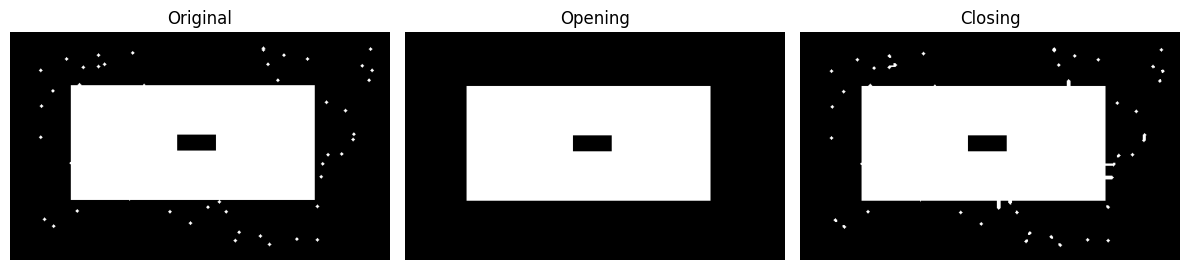

In [11]:
opening = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(mask, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(opening, cmap="gray")
plt.title("Opening")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(closing, cmap="gray")
plt.title("Closing")
plt.axis("off")

plt.tight_layout()
plt.show()

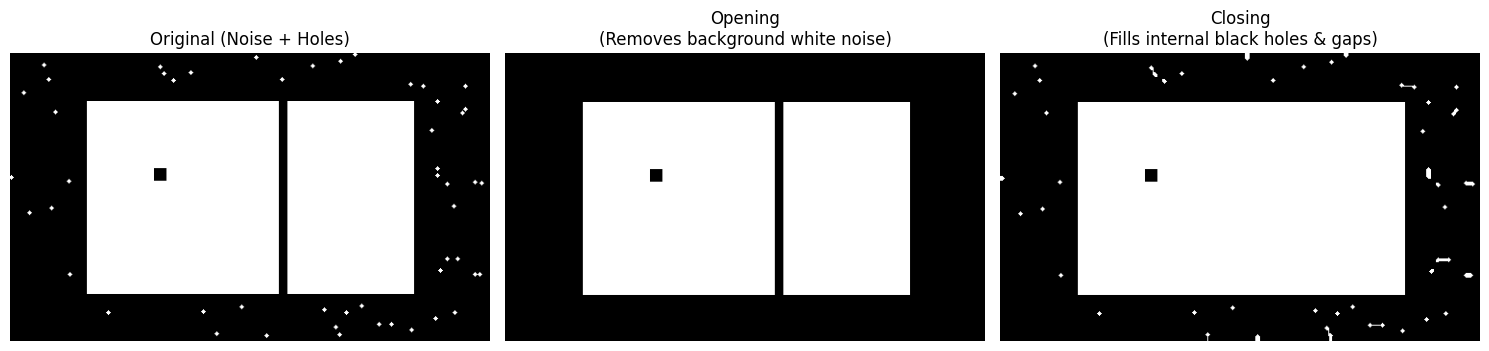

In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Create a black background
mask = np.zeros((300, 500), dtype=np.uint8)

# 2. Draw a large white rectangle
cv2.rectangle(mask, (80, 50), (420, 250), 255, -1)

# --- ADD NOISE FOR OPENING ---
# Add tiny white spots in the background (salt noise)
np.random.seed(42)
for _ in range(120):
    x = np.random.randint(0, 500)
    y = np.random.randint(0, 300)
    # Ensure noise is in the background area
    if x < 70 or x > 430 or y < 40 or y > 260:
        cv2.circle(mask, (x, y), 2, 255, -1)

# --- ADD HOLES/GAPS FOR CLOSING ---
# Add a small black hole inside the rectangle (12x12 pixels)
cv2.rectangle(mask, (150, 120), (162, 132), 0, -1)

# Add a narrow black slice through the rectangle (gap)
cv2.rectangle(mask, (280, 50), (288, 250), 0, -1)


# 3. Define a Structuring Element (Kernel)
# Kernel size (15x15) is larger than the 12px hole and 8px gap
kernel = np.ones((10, 10), np.uint8)

# 4. Apply Opening and Closing
opening = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

# 5. Visualize the comparison
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(mask, cmap="gray")
plt.title("Original (Noise + Holes)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(opening, cmap="gray")
plt.title("Opening\n(Removes background white noise)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(closing, cmap="gray")
plt.title("Closing\n(Fills internal black holes & gaps)")
plt.axis("off")

plt.tight_layout()
plt.show()

## Opening and Closing

### Opening

**Opening = erosion → dilation**
Opening: Wipes away all the isolated white dots in the background, but leaves the inner black hole and gap intact.

It is useful for removing small foreground objects/noise.

### Closing

**Closing = dilation → erosion**

Closing: Completely seals up the 12px black hole and bridges the 8px split line, but keeps the white noise dots in the background.
It is useful for filling small holes and closing small gaps.

A useful memory trick:

- **Opening cleans small white objects** :
Opening removes isolated white objects (background noise, specks) and detaches weakly connected regions.
- **Closing closes small black gaps/holes** :
Closing fills in dark gaps and holes inside or between white objects.

The result depends on the kernel size and shape.

# Lesson 5 — Derivatives and Edge Detection

An edge is usually a location where image intensity changes quickly.

For example:

**dark → bright**

creates a strong intensity change.

We can detect these changes using image derivatives.

The main tools are:

- Sobel X
- Sobel Y
- Gradient magnitude
- Laplacian
- Canny

## Image gradients

Think of an image as a 2D intensity surface.

- **Sobel X** measures intensity changes mainly from left to right.
- **Sobel Y** measures intensity changes mainly from top to bottom.

A strong derivative means that intensity changes quickly in that direction.

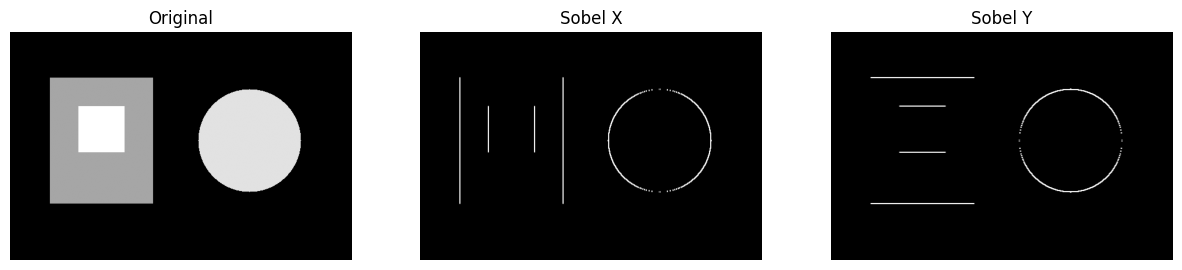

In [15]:
# Use a clean image with clear boundaries
gray = img

sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

# Convert to displayable absolute values
sobel_x_abs = cv2.convertScaleAbs(sobel_x)
sobel_y_abs = cv2.convertScaleAbs(sobel_y)

plt.figure(figsize=(15, 4))

for i, (title, image) in enumerate([
    ("Original", gray),
    ("Sobel X", sobel_x_abs),
    ("Sobel Y", sobel_y_abs)
], 1):
    plt.subplot(1, 3, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.show()

### Why are Sobel X and Sobel Y different?

If an edge is mainly **vertical**, intensity changes as we move horizontally.

So the **X derivative** responds strongly.

If an edge is mainly **horizontal**, intensity changes as we move vertically.

So the **Y derivative** responds strongly.

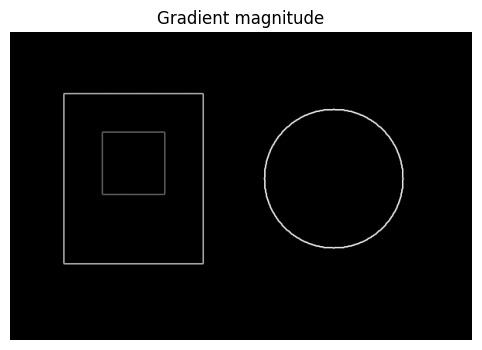

In [16]:
# Gradient magnitude
magnitude = cv2.magnitude(
    sobel_x.astype(np.float32),
    sobel_y.astype(np.float32)
)

magnitude_display = cv2.normalize(
    magnitude, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

plt.figure(figsize=(8, 4))
plt.imshow(magnitude_display, cmap="gray")
plt.title("Gradient magnitude")
plt.axis("off")
plt.show()

## Gradient magnitude

The gradient magnitude combines the X and Y changes.

Conceptually:

**strong X change + strong Y change → strong overall gradient**

This helps us detect edges regardless of their direction.

## Laplacian

The Laplacian uses the second derivative.

It responds strongly to rapid changes in intensity and can highlight edges in multiple directions.

```python
laplacian = cv2.Laplacian(image, cv2.CV_64F)
```

Because derivative operations can also react strongly to noise, smoothing is often useful before edge detection.

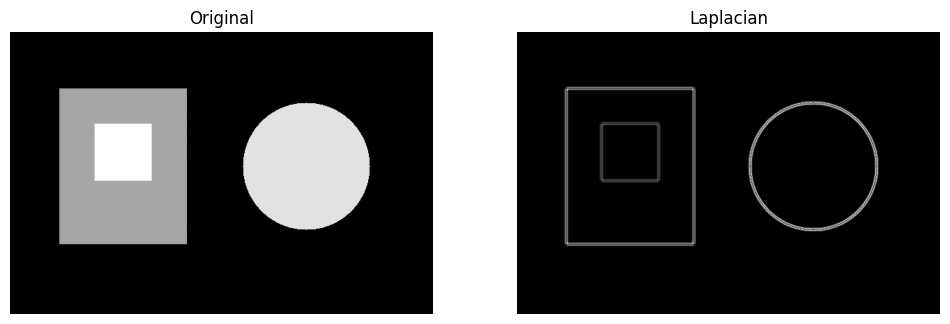

In [17]:
blur_for_edges = cv2.GaussianBlur(gray, (5, 5), 0)

laplacian = cv2.Laplacian(
    blur_for_edges,
    cv2.CV_64F
)

laplacian_abs = cv2.convertScaleAbs(laplacian)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(laplacian_abs, cmap="gray")
plt.title("Laplacian")
plt.axis("off")

plt.show()

# Canny Edge Detection

Canny is a more complete edge-detection pipeline.

A simplified view is:

1. Smooth the image.
2. Calculate gradients.
3. Keep thin/local maximum edges.
4. Use two thresholds.
5. Connect strong edges with relevant weak edges.

OpenCV:

```python
edges = cv2.Canny(image, threshold1, threshold2)
```

The two thresholds are important:

- lower threshold
- upper threshold

Changing them changes how many edges are detected.

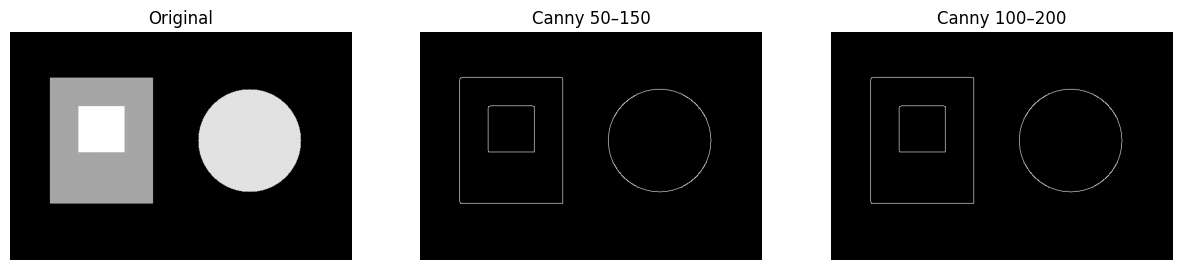

In [18]:
# Canny edge detection
canny_50_150 = cv2.Canny(blur_for_edges, 50, 150)
canny_100_200 = cv2.Canny(blur_for_edges, 100, 200)

plt.figure(figsize=(15, 4))

for i, (title, image) in enumerate([
    ("Original", gray),
    ("Canny 50–150", canny_50_150),
    ("Canny 100–200", canny_100_200)
], 1):
    plt.subplot(1, 3, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.show()

## Why blur before Canny?

Noise creates small intensity changes.

Canny is designed to find intensity changes, so noisy pixels can create unwanted edges.

A common pipeline is:

**Image → Gaussian Blur → Canny**

This is a good example of how the topics in this section work together.

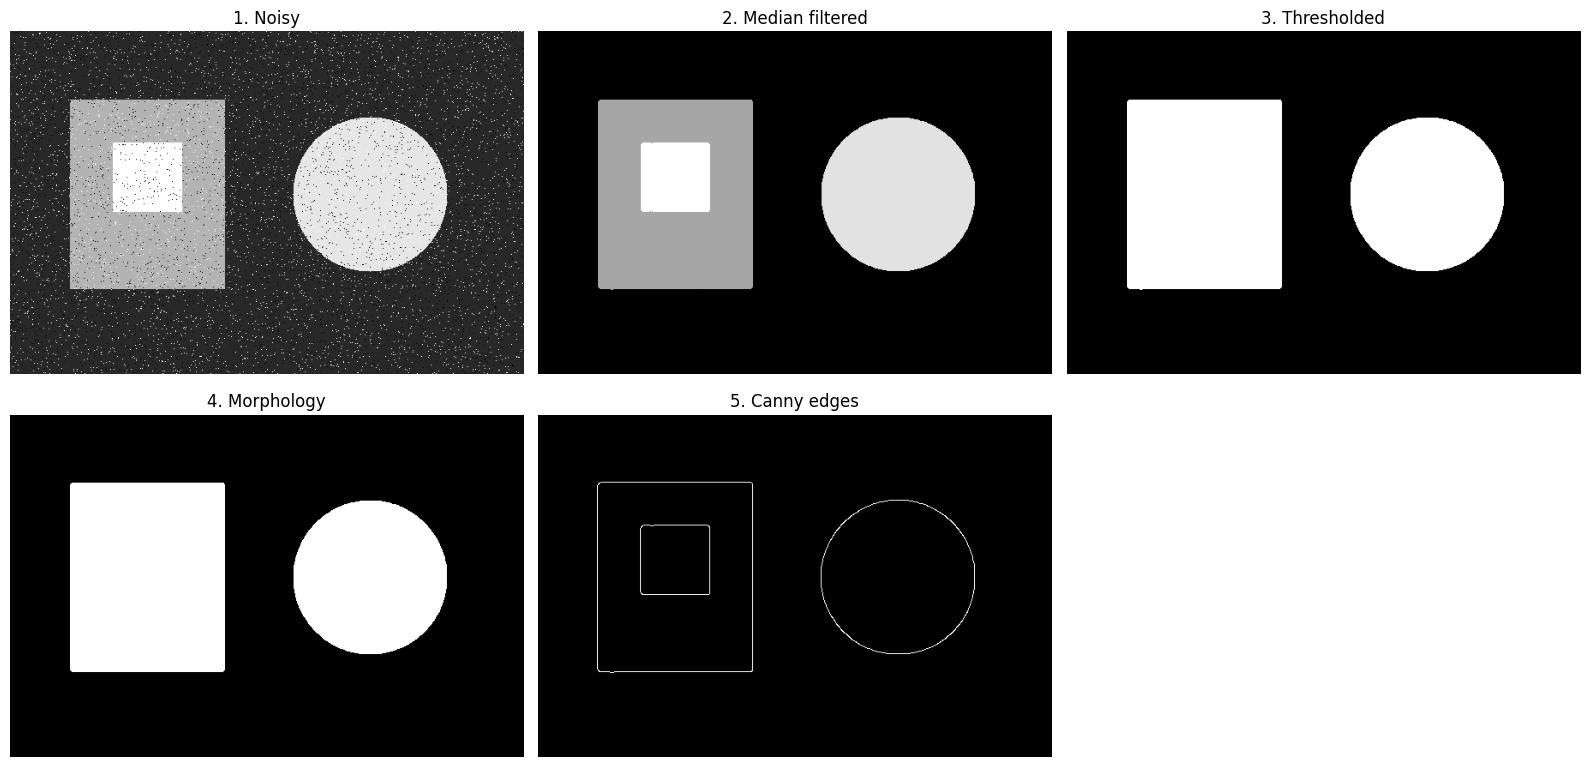

In [19]:
# Complete practical pipeline:
# noisy image -> smoothing -> threshold -> morphology -> edges

np.random.seed(7)
noisy = add_salt_pepper_noise(img, amount=0.02)

# 1. Remove salt-and-pepper noise
cleaned = cv2.medianBlur(noisy, 5)

# 2. Segment foreground
_, segmented = cv2.threshold(
    cleaned, 100, 255, cv2.THRESH_BINARY
)

# 3. Clean the segmentation
kernel = np.ones((5, 5), np.uint8)
segmented_clean = cv2.morphologyEx(
    segmented, cv2.MORPH_OPEN, kernel
)
segmented_clean = cv2.morphologyEx(
    segmented_clean, cv2.MORPH_CLOSE, kernel
)

# 4. Detect edges
edges = cv2.Canny(cleaned, 50, 150)

plt.figure(figsize=(16, 8))

for i, (title, image) in enumerate([
    ("1. Noisy", noisy),
    ("2. Median filtered", cleaned),
    ("3. Thresholded", segmented),
    ("4. Morphology", segmented_clean),
    ("5. Canny edges", edges)
], 1):
    plt.subplot(2, 3, i)
    plt.imshow(image, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

# Quick Comparison

| Task | OpenCV function |
|---|---|
| Average blur | `cv2.blur()` |
| Gaussian smoothing | `cv2.GaussianBlur()` |
| Median smoothing | `cv2.medianBlur()` |
| Bilateral filtering | `cv2.bilateralFilter()` |
| Binary threshold | `cv2.threshold()` |
| Adaptive threshold | `cv2.adaptiveThreshold()` |
| Erosion | `cv2.erode()` |
| Dilation | `cv2.dilate()` |
| Opening | `cv2.morphologyEx(..., cv2.MORPH_OPEN)` |
| Closing | `cv2.morphologyEx(..., cv2.MORPH_CLOSE)` |
| Sobel X/Y | `cv2.Sobel()` |
| Laplacian | `cv2.Laplacian()` |
| Canny | `cv2.Canny()` |

# Mini Practice Tasks

Try these without looking at the previous cells.

### Task 1 — Noise
1. Change Gaussian noise `sigma` from `25` to `50`.
2. Change salt-and-pepper noise from `0.02` to `0.08`.
3. Compare which image becomes harder to recognize.

### Task 2 — Filtering
Apply:
- Gaussian blur with `(3,3)`
- Gaussian blur with `(11,11)`
- median blur with `3`
- median blur with `9`

**Question:** Which filter preserves the object boundaries better?

### Task 3 — Thresholding
Try threshold values:
- `60`
- `120`
- `200`

Then compare with Otsu.

**Question:** When does a manually selected threshold fail?

### Task 4 — Morphology
Change the kernel:
```python
np.ones((3,3), np.uint8)
np.ones((7,7), np.uint8)
np.ones((11,11), np.uint8)
```

Compare opening and closing.

**Question:** What happens when the kernel becomes too large?

### Task 5 — Edge Detection
Try Canny with:
- `(30, 100)`
- `(50, 150)`
- `(100, 200)`

**Question:** Which setting detects more edges? Which produces more unwanted edges?

### Task 6 — Build your own pipeline
Create this pipeline for an image of your choice:

**Read → Grayscale → Add/observe noise → Filter → Threshold → Morphology → Canny**

Explain in comments why you selected each operation.

# Final Challenge — Document Cleanup

Imagine you have a photographed document containing:

- uneven lighting
- small noise
- dark text
- small gaps in letters

Build a pipeline that tries to produce a clean binary document.

Suggested stages:

1. Convert to grayscale.
2. Apply Gaussian or median filtering.
3. Use adaptive thresholding.
4. Apply morphology.
5. Display the original and final result.

### Extension

Try the same image with:
- global thresholding
- Otsu
- adaptive thresholding

Then explain which method works best and **why**.

In [20]:
# Student challenge template
# Replace `document_image` with your own image.

# document_image = cv2.imread("your_image.jpg")
# gray_doc = cv2.cvtColor(document_image, cv2.COLOR_BGR2GRAY)

# Step 1: filtering

# Step 2: adaptive threshold


# Step 3: morphology


# plt.figure(figsize=(12, 4))
# plt.subplot(1, 2, 1)
# plt.imshow(gray_doc, cmap="gray")
# plt.title("Original")
# plt.axis("off")

# plt.subplot(1, 2, 2)
# plt.imshow(clean_doc, cmap="gray")
# plt.title("Cleaned document")
# plt.axis("off")

# plt.show()